# Network Intrusion Detection Using Data Mining

This notebook uses the NSL-KDD dataset to detect malicious network traffic. The business need is to help a security team identify suspicious connections before they become serious cybersecurity incidents.

The project focuses on one data mining task: supervised classification.


## 1.Imported Libraries

The project uses Pandas and NumPy for data handling, Matplotlib and Seaborn for visualization, and Scikit-learn for machine learning models and evaluation metrics.


In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Define Dataset Columns

The NSL-KDD files do not include column names, so the feature names are defined manually. The final two columns are the original attack label and the difficulty score.


In [15]:
columns = [
    'duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes',
    'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins',
    'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root',
    'num_file_creations', 'num_shells', 'num_access_files',
    'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'count',
    'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate',
    'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate',
    'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count',
    'dst_host_same_srv_rate', 'dst_host_diff_srv_rate',
    'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate',
    'dst_host_serror_rate', 'dst_host_srv_serror_rate',
    'dst_host_rerror_rate', 'dst_host_srv_rerror_rate',
    'label', 'difficulty'
]

## 3. Load The Dataset

The project uses the official train/test split from NSL-KDD: `KDDTrain+.txt` for training and `KDDTest+.txt` for testing.


In [16]:
train_data = pd.read_csv('../data/KDDTrain+.txt', names=columns)
test_data = pd.read_csv('../data/KDDTest+.txt', names=columns)

print("Train shape:", train_data.shape)
print("Test shape:", test_data.shape)

train_data.head()

Train shape: (125973, 43)
Test shape: (22544, 43)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


## 4. Create Binary Target Labels

The original dataset contains many attack names. For this project, the labels are converted into a binary target: `0` for normal traffic and `1` for attack traffic.


In [17]:
train_data['target'] = train_data['label'].apply(lambda x: 0 if x == 'normal' else 1)
test_data['target'] = test_data['label'].apply(lambda x: 0 if x == 'normal' else 1)

print("Training data target distribution:")
print(train_data['target'].value_counts())

print("\nTesting data target distribution:")
print(test_data['target'].value_counts())

Training data target distribution:
target
0    67343
1    58630
Name: count, dtype: int64

Testing data target distribution:
target
1    12833
0     9711
Name: count, dtype: int64


## 5. Visualize Class Distribution

This chart shows how many normal and attack records are present in the training data. It helps explain the balance of the classification problem.


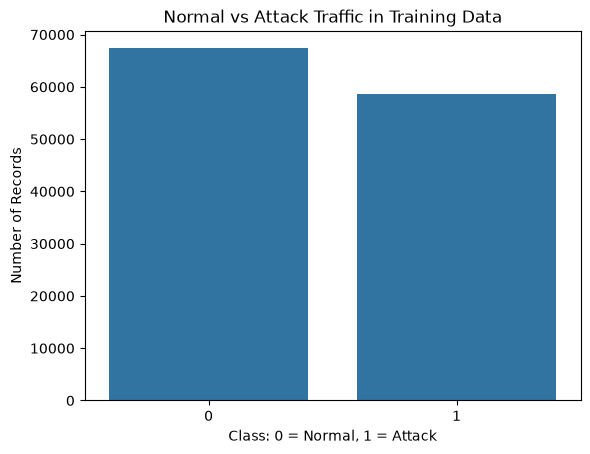

In [18]:
sns.countplot(x='target', data=train_data)
plt.title('Normal vs Attack Traffic in Training Data')
plt.xlabel('Class: 0 = Normal, 1 = Attack')
plt.ylabel('Number of Records')
plt.show()

## 6. Prepare Features And Labels

The target label, original text label, and difficulty column are removed from the feature matrix. The model learns only from network traffic attributes.


In [19]:
X_train = train_data.drop(['label', 'difficulty', 'target'], axis=1)
y_train = train_data['target']

X_test = test_data.drop(['label', 'difficulty', 'target'], axis=1)
y_test = test_data['target']

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (125973, 41)
X_test shape: (22544, 41)


## 7. Encode Categorical Features

The `protocol_type`, `service`, and `flag` columns are categorical. One-hot encoding converts them into numeric columns that Scikit-learn models can use.


In [20]:
categorical_columns = ['protocol_type', 'service', 'flag']

combined = pd.concat([X_train, X_test], axis=0)

combined_encoded = pd.get_dummies(combined, columns=categorical_columns)

X_train_encoded = combined_encoded.iloc[:len(X_train), :]
X_test_encoded = combined_encoded.iloc[len(X_train):, :]

print("Encoded X_train shape:", X_train_encoded.shape)
print("Encoded X_test shape:", X_test_encoded.shape)

Encoded X_train shape: (125973, 122)
Encoded X_test shape: (22544, 122)


## 8. Classification Model 1: Decision Tree

A Decision Tree is trained as a simple and interpretable classification model. It predicts whether each network connection is normal or an attack.


In [21]:
dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train_encoded, y_train)

dt_predictions = dt_model.predict(X_test_encoded)

print("Decision Tree Accuracy:", accuracy_score(y_test, dt_predictions))
print(classification_report(y_test, dt_predictions, target_names=['Normal Traffic', 'Attack Traffic']))

Decision Tree Accuracy: 0.7853087295954577
                precision    recall  f1-score   support

Normal Traffic       0.67      0.97      0.80      9711
Attack Traffic       0.96      0.65      0.77     12833

      accuracy                           0.79     22544
     macro avg       0.82      0.81      0.78     22544
  weighted avg       0.84      0.79      0.78     22544



### Decision Tree Confusion Matrix

The confusion matrix shows correct and incorrect predictions for normal and attack traffic.


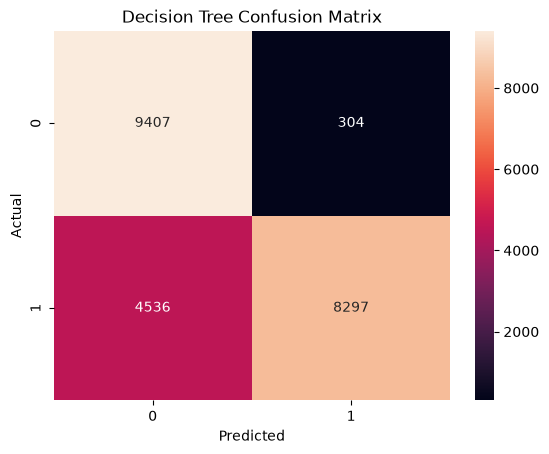

In [22]:
cm = confusion_matrix(y_test, dt_predictions)

sns.heatmap(cm, annot=True, fmt='d')
plt.title('Decision Tree Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

## 9. Classification Model 2: Random Forest

Random Forest combines many decision trees and is usually more stable than a single tree. It is used as the second supervised classification model.


In [23]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

rf_model.fit(X_train_encoded, y_train)

rf_predictions = rf_model.predict(X_test_encoded)

print("Random Forest Accuracy:", accuracy_score(y_test, rf_predictions))
print(classification_report(y_test, rf_predictions, target_names=['Normal Traffic', 'Attack Traffic']))

Random Forest Accuracy: 0.7662349183818311
                precision    recall  f1-score   support

Normal Traffic       0.65      0.97      0.78      9711
Attack Traffic       0.97      0.61      0.75     12833

      accuracy                           0.77     22544
     macro avg       0.81      0.79      0.77     22544
  weighted avg       0.83      0.77      0.76     22544



### Random Forest Confusion Matrix

This matrix helps compare Random Forest predictions against the true labels.


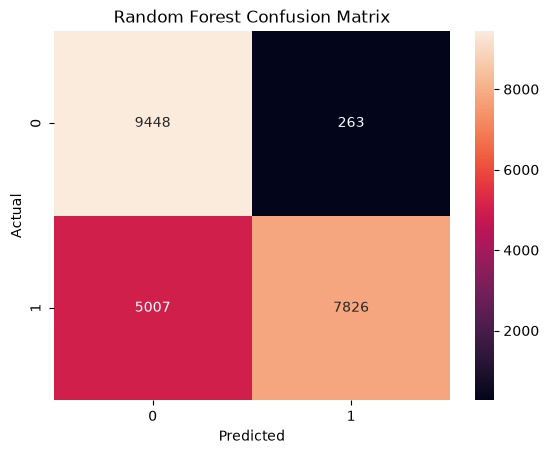

In [24]:
cm = confusion_matrix(y_test, rf_predictions)

sns.heatmap(cm, annot=True, fmt='d')
plt.title('Random Forest Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

## 10. Feature Importance

Feature importance shows which network attributes had the strongest influence on the Random Forest predictions.


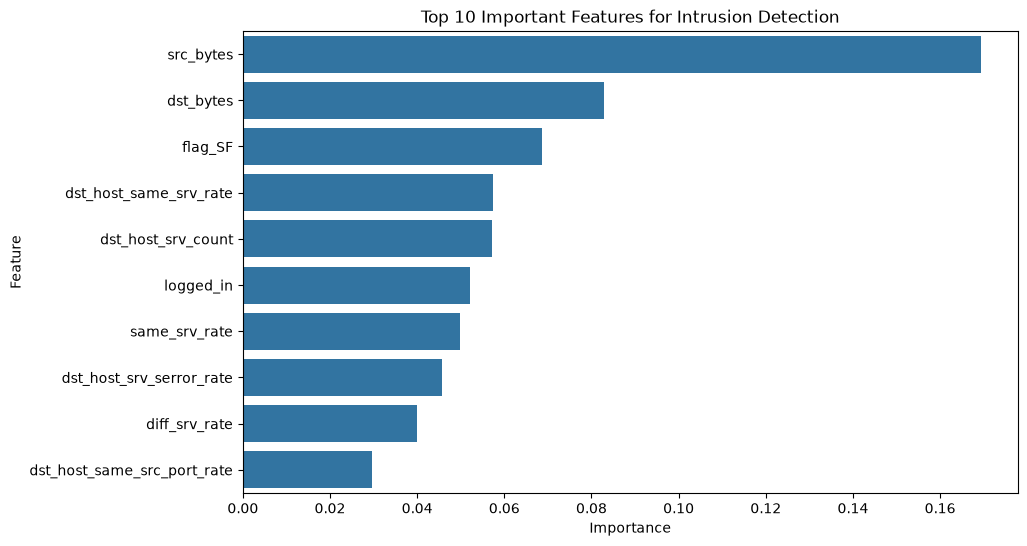

,Feature,Importance
1,src_bytes,0.169369
2,dst_bytes,0.082932
120,flag_SF,0.068727
30,dst_host_same_srv_rate,0.057383
29,dst_host_srv_count,0.057075
8,logged_in,0.052018
25,same_srv_rate,0.049715
35,dst_host_srv_serror_rate,0.045597
26,diff_srv_rate,0.040016
32,dst_host_same_src_port_rate,0.029540


In [25]:
importances = rf_model.feature_importances_

feature_importance = pd.DataFrame({
    'Feature': X_train_encoded.columns,
    'Importance': importances
})

top_features = feature_importance.sort_values(by='Importance', ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=top_features)
plt.title('Top 10 Important Features for Intrusion Detection')
plt.show()

top_features

## 11. Demo Prediction

This final step demonstrates how the trained Random Forest model can classify one network connection from the test set.


In [26]:
sample = X_test_encoded.iloc[[0]]

prediction = rf_model.predict(sample)

if prediction[0] == 0:
    print("Prediction: Normal Traffic")
else:
    print("Prediction: Attack Traffic")

print("Actual label:", test_data.iloc[0]['label'])

Prediction: Attack Traffic
Actual label: neptune
